
Plan: (1) check the data, (2) draw 5 pictures, (3) split 70/30 by time, (4) compare simple baselines with a gradient boosting forecaster.

In [26]:
import gdown
import pandas as pd

file_id = '1KLtkWrC96XvBm9JVJKpzjrHHfix7wW1K'
url = f'https://drive.google.com/uc?id={file_id}'
output = 'dataset.csv'

gdown.download(url, output, quiet=False)

df = pd.read_csv(output).set_index('minute')

print('shape (minutes x apps):', df.shape)
print('days of data:', round(len(df)/1440, 2))
print('missing values:', int(df.isna().sum().sum()))
print('minutes are continuous:', bool((df.index.to_series().diff().dropna() == 1).all()))
print('negative values:', int((df < 0).sum().sum()))

Downloading...
From: https://drive.google.com/uc?id=1KLtkWrC96XvBm9JVJKpzjrHHfix7wW1K
To: /content/dataset.csv
100%|██████████| 38.1M/38.1M [00:00<00:00, 47.1MB/s]


shape (minutes x apps): (20160, 318)
days of data: 14.0
missing values: 0
minutes are continuous: True
negative values: 0


In [25]:
df.head()

,app_64,app_147,app_29,app_189,app_186,app_111,app_17,app_302,app_263,app_138,...,app_182,app_235,app_67,app_77,app_13,app_137,app_68,app_6,app_291,app_244
minute,,,,,,,,,,,,,,,,,,,,,
0,1078.0,2112.0,0.0,156.0,66.0,519.0,4297.0,100.0,88.0,234.0,...,43.0,192.0,22.0,545.0,586.0,298.0,240.0,10954.0,234.0,164.0
1,1202.0,1983.0,0.0,214.0,57.0,625.0,4242.0,142.0,166.0,307.0,...,41.0,181.0,2514.0,528.0,482.0,401.0,242.0,11425.0,330.0,154.0
2,898.0,2061.0,0.0,223.0,69.0,590.0,4137.0,149.0,92.0,401.0,...,39.0,187.0,1525.0,480.0,430.0,275.0,231.0,11273.0,173.0,166.0
3,1087.0,2063.0,0.0,166.0,68.0,715.0,4297.0,85.0,103.0,379.0,...,51.0,182.0,1315.0,460.0,207.0,479.0,261.0,11675.0,157.0,152.0
4,1095.0,1865.0,0.0,167.0,86.0,607.0,4178.0,86.0,111.0,361.0,...,62.0,192.0,880.0,536.0,108.0,463.0,238.0,11594.0,213.0,172.0


In [6]:
mean = df.mean()
stats = pd.DataFrame({
    'mean': mean,
    'max': df.max(),
    'cv': df.std() / mean.replace(0, np.nan),          # burstiness: bigger = more jumpy
    'peak_to_mean': df.max() / mean.replace(0, np.nan),
    'zero_share': (df == 0).mean(),                      # share of minutes with no traffic
})
display(stats.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
mean,318.0,1655.62,7026.34,71.57,175.28,334.43,867.85,89300.46
max,318.0,8027.90,21237.72,107.00,876.00,2146.00,5824.50,217088.00
cv,318.0,0.81,1.05,0.01,0.24,0.52,0.93,9.46
peak_to_mean,318.0,10.59,21.04,1.09,2.45,4.60,8.58,205.63
zero_share,318.0,0.07,0.19,0.00,0.00,0.00,0.01,0.97


## Picture 1: total traffic over time (all apps added together)

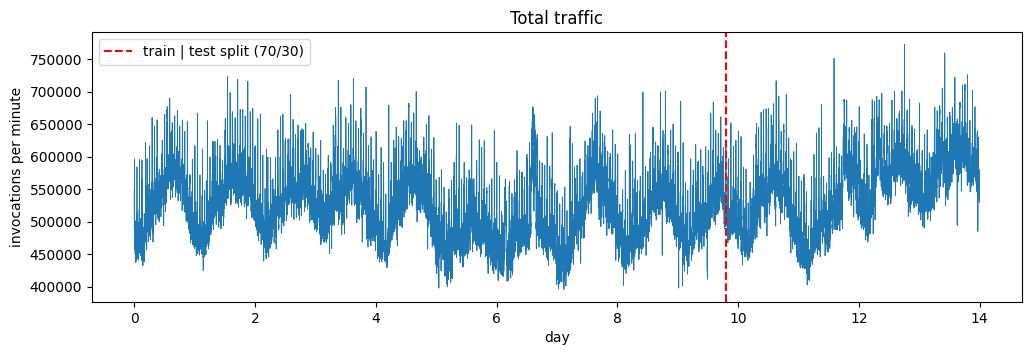

In [7]:
DAY = 1440
n = len(df)
cut = int(n * 0.7)

total = df.sum(axis=1)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(total.index / DAY, total.values, lw=0.6)
ax.axvline(cut / DAY, color='red', ls='--', label='train | test split (70/30)')
ax.set_xlabel('day'); ax.set_ylabel('invocations per minute'); ax.legend()
ax.set_title('Total traffic'); plt.show()

## Picture 2: six sample apps, first 3 days (from busy to quiet)

sample apps: ['app_1', 'app_62', 'app_123', 'app_185', 'app_248', 'app_318']


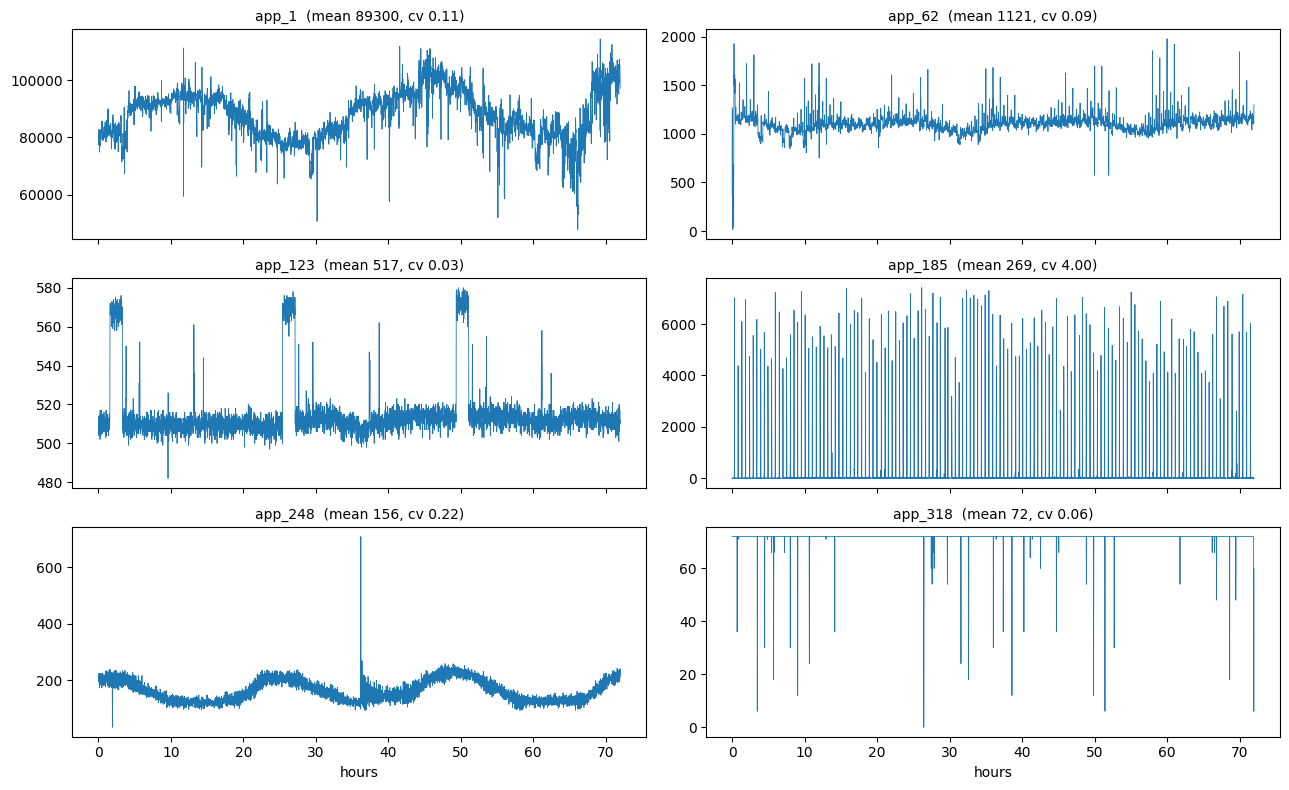

In [8]:
active = stats[stats.zero_share < 0.2].sort_values('mean', ascending=False)
sample = active.iloc[np.linspace(0, len(active) - 1, 6).astype(int)].index.tolist()
print('sample apps:', sample)

fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
for ax, a in zip(axes.ravel(), sample):
    ax.plot(df.index[:3*DAY] / 60, df[a].iloc[:3*DAY], lw=0.6)
    ax.set_title(f"{a}  (mean {stats.loc[a,'mean']:.0f}, cv {stats.loc[a,'cv']:.2f})", fontsize=10)
for ax in axes[-1]: ax.set_xlabel('hours')
plt.tight_layout(); plt.show()

## Picture 3: average day shape (does traffic repeat every 24h?)

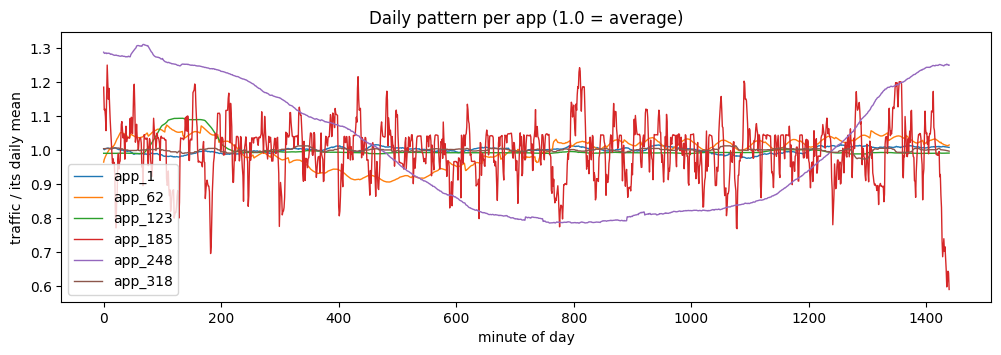

In [9]:
mod = df.index % DAY
daily = df[sample].groupby(mod).mean()
daily = (daily / daily.mean()).rolling(30, center=True, min_periods=1).mean()
ax = daily.plot(figsize=(12, 3.5), lw=1)
ax.set_xlabel('minute of day'); ax.set_ylabel('traffic / its daily mean')
ax.set_title('Daily pattern per app (1.0 = average)'); plt.show()

## Picture 4: which apps are smooth and which are bursty?

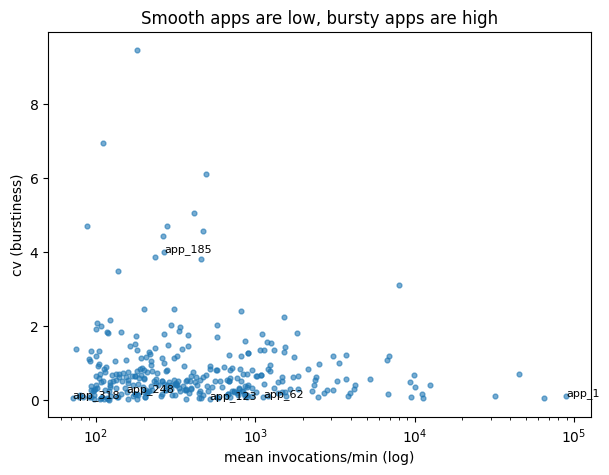

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(stats['mean'], stats['cv'], s=12, alpha=0.6)
for a in sample:
    ax.annotate(a, (stats.loc[a, 'mean'], stats.loc[a, 'cv']), fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('mean invocations/min (log)'); ax.set_ylabel('cv (burstiness)')
ax.set_title('Smooth apps are low, bursty apps are high'); plt.show()

## Forecaster v1
**Task:** at minute `t`, predict traffic at `t + H` (H = 10 minutes, because a new replica takes about 2 minutes to start and you want to act early).

**Fair test rules**
- Features use only the past (up to minute `t`).
- Train rows: only those whose target is still inside the first 70%.
- Test rows: the last 30%.

**Methods compared**
1. `naive`: traffic in 10 minutes = traffic now
2. `moving_avg`: average of the last 10 minutes
3. `yesterday`: traffic at the same minute yesterday
4. `gbm`: gradient boosting on recent lags + yesterday + time of day
5. `gbm_q90`: same, but trained to predict the 90th percentile, so it errs on the high side (safer for an autoscaler)

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

H = 10

def make_features(s, H):
    x = np.log1p(s)
    X = pd.DataFrame(index=s.index)
    for k in [0, 1, 2, 3, 5, 10, 20, 30, 60]:
        X[f'lag{k}'] = x.shift(k)
    X['mean10'] = x.rolling(10).mean()
    X['mean60'] = x.rolling(60).mean()
    X['std10'] = x.rolling(10).std()
    X['yday_target'] = x.shift(DAY - H)                        # yesterday, same minute as the target
    X['yday_change'] = x.shift(DAY - H) - x.shift(DAY)         # how much traffic moved yesterday over the same 10 min
    m = s.index % DAY
    X['sin'] = np.sin(2 * np.pi * m / DAY)
    X['cos'] = np.cos(2 * np.pi * m / DAY)
    return X

def score(actual, pred):
    err = pred - actual
    return {
        'WAPE': err.abs().sum() / actual.sum(),           # total error / total traffic (lower = better)
        'under_10pct': (pred < 0.9 * actual).mean(),       # share of minutes predicted >10% too LOW (risky)
        'over_10pct': (pred > 1.1 * actual).mean(),        # share of minutes predicted >10% too HIGH (wasteful)
    }

rows, preds_store = [], {}
for a in sample:
    s = df[a].astype(float)
    X = make_features(s, H)
    y_log = np.log1p(s).shift(-H)
    actual = s.shift(-H)

    train_idx = X.index[(X.index < cut - H)]
    test_idx = X.index[(X.index >= cut) & (X.index < n - H)]
    tr = X.loc[train_idx].dropna().index
    te = X.loc[test_idx].dropna().index

    preds = {
        'naive': s.loc[te],
        'moving_avg': s.rolling(10).mean().loc[te],
        'yesterday': s.shift(DAY - H).loc[te],
    }
    gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=6, random_state=0)
    gbm.fit(X.loc[tr], y_log.loc[tr])
    preds['gbm'] = pd.Series(np.expm1(gbm.predict(X.loc[te])), index=te)

    gq = HistGradientBoostingRegressor(loss='quantile', quantile=0.9, max_iter=300,
                                       learning_rate=0.05, max_depth=6, random_state=0)
    gq.fit(X.loc[tr], y_log.loc[tr])
    preds['gbm_q90'] = pd.Series(np.expm1(gq.predict(X.loc[te])), index=te)

    for name, p in preds.items():
        rows.append({'app': a, 'method': name, **score(actual.loc[te], p)})
    preds_store[a] = (actual.loc[te], preds)

res = pd.DataFrame(rows)
print('train minutes:', len(tr), '| test minutes:', len(te))
display(res.pivot(index='app', columns='method', values='WAPE').round(3))

train minutes: 12662 | test minutes: 6038


method,gbm,gbm_q90,moving_avg,naive,yesterday
app,,,,,
app_1,0.038,0.061,0.034,0.045,0.133
app_123,0.011,0.015,0.009,0.011,0.016
app_185,0.992,1.630,1.960,1.985,1.829
app_248,0.056,0.099,0.077,0.063,0.131
app_318,0.022,0.007,0.014,0.015,0.012
app_62,0.025,0.037,0.039,0.048,0.031


## Result: average over the 6 apps

,WAPE,under_10pct,over_10pct
method,,,
gbm,0.191,0.069,0.144
gbm_q90,0.308,0.019,0.258
moving_avg,0.356,0.064,0.174
yesterday,0.359,0.157,0.188
naive,0.361,0.102,0.109


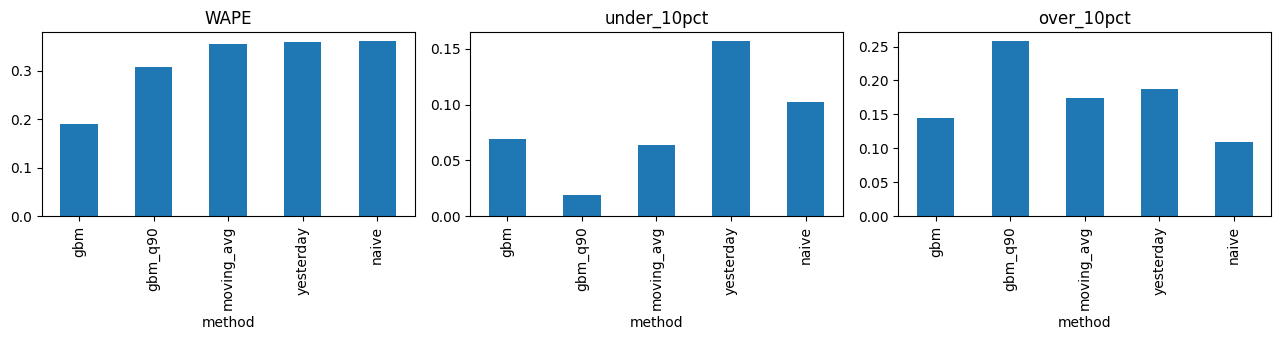

In [12]:
summary = res.groupby('method')[['WAPE', 'under_10pct', 'over_10pct']].mean().round(3).sort_values('WAPE')
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['WAPE', 'under_10pct', 'over_10pct']):
    summary[col].plot.bar(ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

## Picture 5: one test day, actual vs predicted

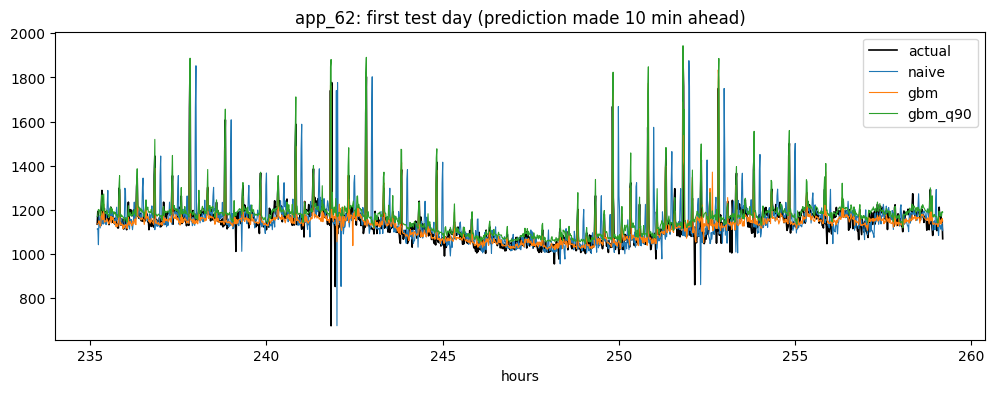

In [13]:
a = sample[1]
actual, preds = preds_store[a]
w = actual.index[:DAY]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w / 60, actual.loc[w], label='actual', lw=1.2, color='black')
for m in ['naive', 'gbm', 'gbm_q90']:
    ax.plot(w / 60, preds[m].loc[w], label=m, lw=0.8)
ax.set_xlabel('hours'); ax.set_title(f'{a}: first test day (prediction made {H} min ahead)'); ax.legend(); plt.show()

## LSTM (PyTorch) - same test as the GBM
Same rows, same features, same score function. The LSTM reads the last 60 minutes. It also gets yesterday's value and time of day.

In [14]:
import torch, torch.nn as nn, time
device = 'cuda' if torch.cuda.is_available() else 'cpu'
W = 60            # minutes of history the LSTM reads
print('device:', device)

class LSTMForecaster(nn.Module):
    def __init__(self, n_static, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_static, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, seq, static):
        _, (h, _) = self.lstm(seq.unsqueeze(-1))
        return self.head(torch.cat([h[-1], static], dim=1)).squeeze(1)

def pinball(q):
    def f(pred, y):
        e = y - pred
        return torch.mean(torch.maximum(q * e, (q - 1) * e))
    return f

def windows(x, idx):
    return x[idx[:, None] + np.arange(-W + 1, 1)[None, :]]

def fit_lstm(seq, st, y, loss_fn, epochs=40, seed=0):
    torch.manual_seed(seed)
    k = int(len(y) * 0.9)                       # last 10% of train = validation (time order kept)
    t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    seq, st, y = t(seq), t(st), t(y)
    model = LSTMForecaster(st.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    best, best_state = 1e9, None
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(k, device=device)
        for i in range(0, k, 256):
            b = perm[i:i + 256]
            opt.zero_grad()
            loss_fn(model(seq[b], st[b]), y[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(seq[k:], st[k:]), y[k:]).item()
        if v < best:
            best, best_state = v, {a: b.clone() for a, b in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

rows_l, preds_lstm = [], {}
t0 = time.time()
for a in sample:
    s = df[a].astype(float)
    X = make_features(s, H)
    x = np.log1p(s.values)
    y_log = np.log1p(s).shift(-H)

    actual = preds_store[a][0]                  # exact same test rows as the GBM
    te = actual.index
    tr = X.loc[X.index < cut - H].dropna().index

    mu, sd = x[tr].mean(), max(x[tr].std(), 1e-6)
    def build(idx):
        seq = (windows(x, idx.values) - mu) / sd
        st = np.c_[(X.loc[idx, 'yday_target'].values - mu) / sd,
                   X.loc[idx, 'yday_change'].values / sd,
                   X.loc[idx, 'sin'].values, X.loc[idx, 'cos'].values]
        return seq, st
    seq_tr, st_tr = build(tr); seq_te, st_te = build(te)

    d_tr = y_log.loc[tr].values - x[tr]         # predict the CHANGE in log traffic
    dsd = max(d_tr.std(), 1e-6)
    y_tr = d_tr / dsd

    preds_lstm[a] = {}
    for name, lf in [('lstm', nn.MSELoss()), ('lstm_q90', pinball(0.9))]:
        m = fit_lstm(seq_tr, st_tr, y_tr, lf)
        with torch.no_grad():
            out = m(torch.tensor(seq_te, dtype=torch.float32, device=device),
                    torch.tensor(st_te, dtype=torch.float32, device=device)).cpu().numpy()
        p = pd.Series(np.clip(np.expm1(out * dsd + x[te]), 0, None), index=te)
        preds_lstm[a][name] = p
        rows_l.append({'app': a, 'method': name, **score(actual, p)})
    print(a, 'done', round(time.time() - t0), 's')

res_lstm = pd.DataFrame(rows_l)
res_all = pd.concat([res, res_lstm], ignore_index=True)   # res stays untouched

device: cuda
app_1 done 18 s
app_62 done 28 s
app_123 done 39 s
app_185 done 49 s
app_248 done 59 s
app_318 done 70 s


method,gbm,gbm_q90,lstm,lstm_q90,moving_avg,naive,yesterday
app,,,,,,,
app_1,0.038,0.061,0.038,0.063,0.034,0.045,0.133
app_123,0.011,0.015,0.011,0.015,0.009,0.011,0.016
app_185,0.992,1.630,0.984,2.599,1.960,1.985,1.829
app_248,0.056,0.099,0.058,0.098,0.077,0.063,0.131
app_318,0.022,0.007,0.015,0.009,0.014,0.015,0.012
app_62,0.025,0.037,0.027,0.046,0.039,0.048,0.031


,WAPE,under_10pct,over_10pct
method,,,
lstm,0.189,0.068,0.139
gbm,0.191,0.069,0.144
gbm_q90,0.308,0.019,0.258
moving_avg,0.356,0.064,0.174
yesterday,0.359,0.157,0.188
naive,0.361,0.102,0.109
lstm_q90,0.472,0.014,0.266


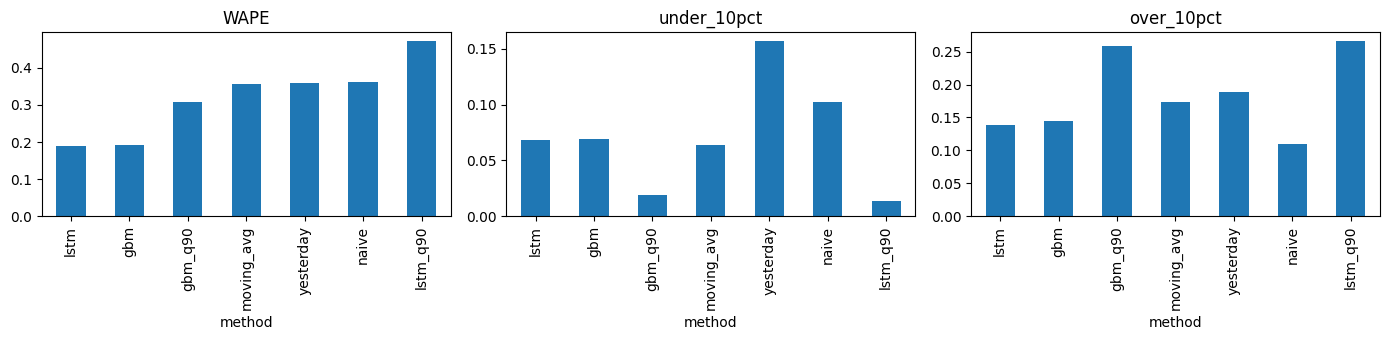

In [15]:
display(res_all.pivot(index='app', columns='method', values='WAPE').round(3))

summary_all = (res_all.groupby('method')[['WAPE', 'under_10pct', 'over_10pct']]
               .mean().round(3).sort_values('WAPE'))
display(summary_all)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ['WAPE', 'under_10pct', 'over_10pct']):
    summary_all[col].plot.bar(ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

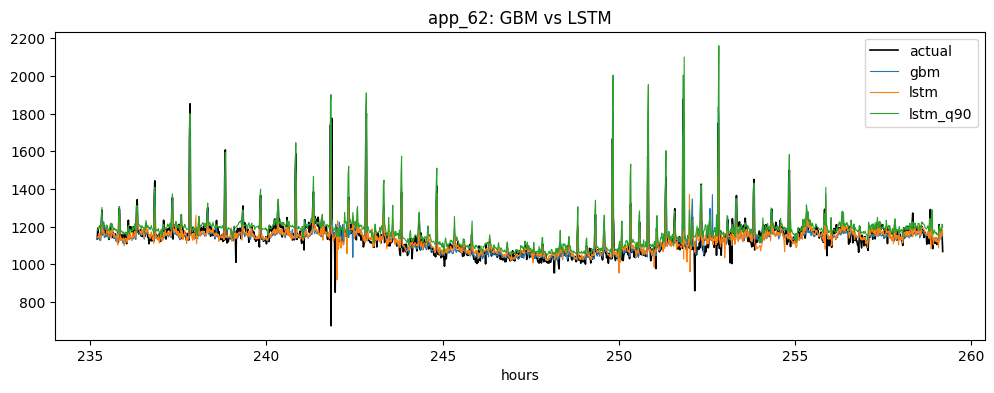

In [16]:
a = sample[1]
actual = preds_store[a][0]
w = actual.index[:DAY]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w / 60, actual.loc[w], label='actual', lw=1.2, color='black')
ax.plot(w / 60, preds_store[a][1]['gbm'].loc[w], label='gbm', lw=0.8)
ax.plot(w / 60, preds_lstm[a]['lstm'].loc[w], label='lstm', lw=0.8)
ax.plot(w / 60, preds_lstm[a]['lstm_q90'].loc[w], label='lstm_q90', lw=0.8)
ax.set_xlabel('hours'); ax.set_title(f'{a}: GBM vs LSTM'); ax.legend(); plt.show()

In [17]:
import os, json, joblib, shutil
from sklearn.ensemble import HistGradientBoostingRegressor
from google.colab import files

# 1. pick best trainable model (baselines like naive/moving_avg are not models)
trainable = [m for m in ['gbm', 'gbm_q90', 'lstm', 'lstm_q90'] if m in summary_all.index]
best = summary_all.loc[trainable, 'WAPE'].idxmin()
print('best model:', best, '| WAPE:', summary_all.loc[best, 'WAPE'])
print('best overall (incl. baselines):', summary_all['WAPE'].idxmin())

# 2. retrain it for every app and save
OUT = f'/content/aegiscloud_best_{best}'
shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT)

for a in sample:
    s = df[a].astype(float)
    X = make_features(s, H)
    x = np.log1p(s.values)
    y_log = np.log1p(s).shift(-H)
    tr = X.loc[X.index < cut - H].dropna().index

    if best.startswith('gbm'):
        kw = dict(loss='quantile', quantile=0.9) if best == 'gbm_q90' else {}
        model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                              max_depth=6, random_state=0, **kw)
        model.fit(X.loc[tr], y_log.loc[tr])
        joblib.dump({'model': model, 'features': list(X.columns)}, f'{OUT}/{a}.joblib')
    else:
        mu, sd = x[tr].mean(), max(x[tr].std(), 1e-6)
        seq = (windows(x, tr.values) - mu) / sd
        st = np.c_[(X.loc[tr, 'yday_target'].values - mu) / sd,
                   X.loc[tr, 'yday_change'].values / sd,
                   X.loc[tr, 'sin'].values, X.loc[tr, 'cos'].values]
        d = y_log.loc[tr].values - x[tr]
        dsd = max(d.std(), 1e-6)
        lf = nn.MSELoss() if best == 'lstm' else pinball(0.9)
        m = fit_lstm(seq, st, d / dsd, lf)
        torch.save({'state': m.state_dict(), 'mu': float(mu), 'sd': float(sd),
                    'dsd': float(dsd), 'n_static': 4, 'W': W, 'H': H}, f'{OUT}/{a}.pt')
    print('saved', a)

json.dump({'method': best, 'H': H, 'W': W, 'apps': sample}, open(f'{OUT}/meta.json', 'w'))

# 3. zip and download
shutil.make_archive(OUT, 'zip', OUT)
files.download(OUT + '.zip')

best model: lstm | WAPE: 0.189
best overall (incl. baselines): lstm
saved app_1
saved app_62
saved app_123
saved app_185
saved app_248
saved app_318


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>